

# 02 — Xenium Spatial Transcriptomics: Data Inspection and Quality Control

### Overview
This notebook begins the characterization of a publicly available legacy Xenium spatial transcriptomics dataset from human colorectal cancer tissue.

The dataset was generated using the 10x Genomics Xenium In Situ platform with the 325-gene Human Colon Gene Expression Panel. The selected sample consists of FFPE-preserved stage IIA colon adenocarcinoma tissue.

**The initial analysis uses the Xenium Explorer subset (3.56 GB), rather than the full Xenium output bundle (20.4 GB).** This subset will first be inspected to determine its structure, available data, and compatibility with downstream computational analysis.

If the subset contains the necessary expression and spatial information, it will be used for initial characterization and quality assessment. Additional files from the full Xenium output will be obtained if required.

### Objectives

#### Part 1 — Xenium Explorer Subset Inspection
1. Identify and inspect the extracted Xenium files.
2. Examine the structure and contents of the Zarr archives.
3. Determine how expression matrices and cell metadata are stored.
4. Verify the availability of gene identifiers and spatial coordinates.
5. Determine whether the subset is sufficient for downstream analysis.

#### Part 2 — Dataset Characterization and Quality Control
1. Load the cell-by-gene expression matrix.
2. Determine the number of cells and measured genes.
3. Examine transcript counts and gene detection per cell.
4. Evaluate gene detection frequencies and expression distributions.
5. Generate cell-level and gene-level QC visualizations.
6. Assess spatial distributions and potential quality issues.
7. Determine whether additional filtering or preprocessing is necessary.

#### Part 3 — Downstream Data Preparation
1. Organize expression and spatial metadata.
2. Convert the data into AnnData format, if feasible.
3. Save QC summaries, figures, and processed data.
4. Prepare the dataset for integration with the scRNA-seq reference.

### Dataset Information
- **Source:** 10x Genomics public datasets
- **Technology:** Xenium In Situ Gene Expression
- **Tissue:** Human colon adenocarcinoma (stage IIA)
- **Sample:** Cancer, pre-designed panel
- **Gene panel:** 325 genes
- **Downloaded data:** Xenium Explorer subset (3.56 GB)
- **Full output bundle:** 20.4 GB (not downloaded)
- **Data format:** Zarr archives
- **Potential scRNA-seq reference:** GEO GSE289314

### Expected Outputs
- Inventory of Xenium Explorer subset files
- Assessment of data availability and usability
- Dataset dimensions and characteristics
- Preliminary QC statistics and visualizations
- Processed expression data, if supported by the subset
- Determination of whether additional Xenium files are required

### Important Considerations
The Xenium Explorer subset may differ from the standard Xenium output format. File compatibility and data completeness will therefore be evaluated before beginning preprocessing.

Quality-control thresholds will be determined from the observed data distributions. No cells or genes will be removed automatically.


In [1]:

from pathlib import Path
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Project directories
PROJECT_ROOT = Path.cwd().parent

XENIUM_DIR = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "spatial"
    / "xenium_colon_cancer"
    / "Xenium_V1_hColon_Cancer_Base_FFPE_xe_outs"
)

FIGURE_DIR = PROJECT_ROOT / "results" / "figures"
TABLE_DIR = PROJECT_ROOT / "results" / "tables"

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

print("Xenium directory exists:", XENIUM_DIR.exists())

for file in sorted(XENIUM_DIR.iterdir()):
    print(file.name)


Xenium directory exists: True
analysis.zarr.zip
analysis_summary.html
cell_feature_matrix.zarr.zip
cells.zarr.zip
experiment.xenium
morphology_mip.ome.tif
transcripts.zarr.zip



## 2. Inspect Xenium Explorer Zarr Archives

The downloaded Xenium Explorer subset contains compressed Zarr archives rather than the standard Xenium output files.

Before loading the dataset, the internal structure of these archives will be examined to identify the expression matrix, cell metadata, gene identifiers, and spatial information.

This step will determine whether the subset contains sufficient information for downstream quality control and gene-imputation analysis.


In [2]:

import zipfile

# Identify Zarr archives
zarr_files = sorted(XENIUM_DIR.glob("*.zarr.zip"))

print(f"Number of Zarr archives: {len(zarr_files)}")

for file in zarr_files:
    print(f"\n{'=' * 60}")
    print(f"Archive: {file.name}")

    with zipfile.ZipFile(file, "r") as archive:
        contents = archive.namelist()

        print(f"Total entries: {len(contents)}")
        print("\nFirst 15 entries:")

        for entry in contents[:15]:
            print("  ", entry)


Number of Zarr archives: 4

Archive: analysis.zarr.zip
Total entries: 53

First 15 entries:
   .zgroup
   cell_groups/.zgroup
   cell_groups/.zattrs
   cell_groups/0/.zgroup
   cell_groups/0/indices/.zarray
   cell_groups/0/indices/0
   cell_groups/0/indptr/.zarray
   cell_groups/0/indptr/0
   cell_groups/1/.zgroup
   cell_groups/1/indices/.zarray
   cell_groups/1/indices/0
   cell_groups/1/indptr/.zarray
   cell_groups/1/indptr/0
   cell_groups/2/.zgroup
   cell_groups/2/indices/.zarray

Archive: cell_feature_matrix.zarr.zip
Total entries: 11

First 15 entries:
   .zgroup
   cell_features/.zgroup
   cell_features/.zattrs
   cell_features/indices/.zarray
   cell_features/indices/0
   cell_features/indptr/.zarray
   cell_features/indptr/0
   cell_features/data/.zarray
   cell_features/data/0
   cell_features/cell_id/.zarray
   cell_features/cell_id/0.0

Archive: cells.zarr.zip
Total entries: 4268

First 15 entries:
   .zgroup
   .zattrs
   polygon_num_vertices/.zarray
   polygon_num_ver


## 3. Inspect the Cell-Feature Expression Matrix

The `cell_feature_matrix.zarr.zip` archive contains the Xenium expression data in Zarr format.

This step examines the archive's internal structure to identify the expression matrix, gene identifiers, and cell identifiers without loading the complete dataset into memory.

The results will help determine how to convert the Xenium Explorer data into a format suitable for downstream quality control and gene-imputation analysis.


In [3]:

import zipfile

matrix_file = XENIUM_DIR / "cell_feature_matrix.zarr.zip"

with zipfile.ZipFile(matrix_file, "r") as archive:
    contents = archive.namelist()

    # Show only Zarr metadata files
    metadata_files = [
        name for name in contents
        if name.endswith((".zgroup", ".zarray", ".zattrs"))
    ]

    print("Total archive entries:", len(contents))
    print("Metadata files:", len(metadata_files))

    print("\nZarr structure:")
    for name in metadata_files:
        print(name)


Total archive entries: 11
Metadata files: 7

Zarr structure:
.zgroup
cell_features/.zgroup
cell_features/.zattrs
cell_features/indices/.zarray
cell_features/indptr/.zarray
cell_features/data/.zarray
cell_features/cell_id/.zarray



## 4. Examine Expression Matrix Metadata

The cell-feature matrix is stored in a compressed sparse representation within the Xenium Explorer Zarr archive.

This step examines the array metadata to determine matrix dimensions, data types, and storage structure without loading the complete expression matrix.

The metadata will also be used to identify information required to reconstruct a cell-by-gene expression matrix for downstream analysis.


In [4]:

import json
import zipfile

matrix_file = XENIUM_DIR / "cell_feature_matrix.zarr.zip"

with zipfile.ZipFile(matrix_file, "r") as archive:

    # Inspect group attributes
    attrs = json.loads(
        archive.read("cell_features/.zattrs")
    )

    print("CELL FEATURE ATTRIBUTES:")
    print(json.dumps(attrs, indent=2))

    # Inspect individual array metadata
    arrays = [
        "indices",
        "indptr",
        "data",
        "cell_id"
    ]

    for array in arrays:
        metadata = json.loads(
            archive.read(f"cell_features/{array}/.zarray")
        )

        print(f"\n{array.upper()}")
        print("Shape:", metadata.get("shape"))
        print("Data type:", metadata.get("dtype"))
        print("Chunks:", metadata.get("chunks"))


CELL FEATURE ATTRIBUTES:
{
  "feature_ids": [
    "ENSG00000006071",
    "ENSG00000248144",
    "ENSG00000150594",
    "ENSG00000169129",
    "ENSG00000144891",
    "ENSG00000196139",
    "ENSG00000162482",
    "ENSG00000137124",
    "ENSG00000145362",
    "ENSG00000146205",
    "ENSG00000135046",
    "ENSG00000104537",
    "ENSG00000130203",
    "ENSG00000240583",
    "ENSG00000103375",
    "ENSG00000109321",
    "ENSG00000138639",
    "ENSG00000004848",
    "ENSG00000183734",
    "ENSG00000172238",
    "ENSG00000135407",
    "ENSG00000160862",
    "ENSG00000198488",
    "ENSG00000153064",
    "ENSG00000156127",
    "ENSG00000064787",
    "ENSG00000039987",
    "ENSG00000142959",
    "ENSG00000102010",
    "ENSG00000139618",
    "ENSG00000173372",
    "ENSG00000173369",
    "ENSG00000108561",
    "ENSG00000159189",
    "ENSG00000187699",
    "ENSG00000133742",
    "ENSG00000104267",
    "ENSG00000167434",
    "ENSG00000168748",
    "ENSG00000163618",
    "ENSG00000172137",
    "ENSG00


## 5. Summarize Xenium Expression Matrix Structure

The Xenium Explorer expression archive contains cell identifiers, gene identifiers, and sparse expression data.

This step summarizes the number of cells and genes, examines the sparse matrix arrays, and identifies the metadata needed to reconstruct the expression matrix without loading the complete dataset into memory.


In [5]:

import json
import zipfile

with zipfile.ZipFile(matrix_file, "r") as archive:

    attrs = json.loads(
        archive.read("cell_features/.zattrs")
    )

    print("CELL FEATURE METADATA")
    print("---------------------")

    print("Attribute keys:", list(attrs.keys()))

    for key in ["feature_ids", "feature_names"]:
        if key in attrs:
            print(f"{key} count:", len(attrs[key]))
            print(f"First 5 {key}:", attrs[key][:5])

    print("\nSPARSE MATRIX ARRAYS")
    print("---------------------")

    for array in ["data", "indices", "indptr", "cell_id"]:
        metadata = json.loads(
            archive.read(f"cell_features/{array}/.zarray")
        )

        print(
            f"{array}: "
            f"shape={metadata['shape']}, "
            f"dtype={metadata['dtype']}"
        )


CELL FEATURE METADATA
---------------------
Attribute keys: ['feature_ids', 'feature_keys', 'feature_types', 'major_version', 'minor_version', 'number_cells', 'number_features']
feature_ids count: 542
First 5 feature_ids: ['ENSG00000006071', 'ENSG00000248144', 'ENSG00000150594', 'ENSG00000169129', 'ENSG00000144891']

SPARSE MATRIX ARRAYS
---------------------
data: shape=[22146814], dtype=<u4
indices: shape=[22146814], dtype=<u4
indptr: shape=[543], dtype=<u4
cell_id: shape=[647524, 2], dtype=<u4



## 6. Inspect Xenium Feature Annotations

The Xenium Explorer expression matrix contains 542 features, exceeding the advertised 325-gene panel.

This step examines the feature identifiers, feature types, and associated annotations to distinguish biological genes from controls or other assay features.

The resulting feature inventory will help determine which features should be retained for downstream gene-expression analysis and imputation.


In [6]:

import pandas as pd
import json
import zipfile

with zipfile.ZipFile(matrix_file, "r") as archive:
    attrs = json.loads(
        archive.read("cell_features/.zattrs")
    )

print("Available attributes:")
print(list(attrs.keys()))

print("\nFeature annotation lengths:")
for key, value in attrs.items():
    if isinstance(value, list):
        print(f"{key}: {len(value)}")

# Build feature annotation table
feature_df = pd.DataFrame({
    "feature_id": attrs["feature_ids"],
    "feature_key": attrs["feature_keys"],
    "feature_type": attrs["feature_types"]
})

print("\nFeature type counts:")
print(feature_df["feature_type"].value_counts(dropna=False))

print("\nFirst 10 features:")
display(feature_df.head(10))


Available attributes:
['feature_ids', 'feature_keys', 'feature_types', 'major_version', 'minor_version', 'number_cells', 'number_features']

Feature annotation lengths:
feature_ids: 542
feature_keys: 542
feature_types: 542

Feature type counts:
feature_type
gene                         325
unassigned_codeword          155
negative_control_codeword     41
negative_control_probe        20
aggregate_gene                 1
Name: count, dtype: int64

First 10 features:


,feature_id,feature_key,feature_type
0,ENSG00000006071,ABCC8,gene
1,ENSG00000248144,ADH1C,gene
2,ENSG00000150594,ADRA2A,gene
3,ENSG00000169129,AFAP1L2,gene
4,ENSG00000144891,AGTR1,gene
5,ENSG00000196139,AKR1C3,gene
6,ENSG00000162482,AKR7A3,gene
7,ENSG00000137124,ALDH1B1,gene
8,ENSG00000145362,ANK2,gene
9,ENSG00000146205,ANO7,gene



## 7. Inspect Zarr Storage Compatibility

The Xenium Explorer expression archive contains 325 biological genes and 217 additional control or aggregate features.

The expression matrix is stored in compressed sparse format, with 647,524 cells and 542 total features.

This step checks whether the existing Python environment supports reading the compressed Zarr archive directly. The matrix will not be reconstructed or loaded into memory until its storage compatibility has been confirmed.


In [7]:

import importlib.metadata as metadata
import zarr

print("Zarr version:", metadata.version("zarr"))

matrix_file = XENIUM_DIR / "cell_feature_matrix.zarr.zip"

try:
    store = zarr.storage.ZipStore(
        str(matrix_file),
        mode="r"
    )

    root = zarr.open_group(store=store, mode="r")

    print("\nZarr archive opened successfully!")
    print("Top-level groups:", list(root.group_keys()))

    cell_features = root["cell_features"]

    print("Available arrays:", list(cell_features.array_keys()))
    print("Available attributes:", list(cell_features.attrs.keys()))

    store.close()

except Exception as e:
    print("\nUnable to open Zarr archive directly.")
    print("Error type:", type(e).__name__)
    print("Error message:", str(e))


Zarr version: 3.3.0

Zarr archive opened successfully!
Top-level groups: ['cell_features']
Available arrays: ['indices', 'indptr', 'data', 'cell_id']
Available attributes: ['feature_ids', 'feature_keys', 'feature_types', 'major_version', 'minor_version', 'number_cells', 'number_features']



## 8. Load Xenium Sparse Expression Matrix

The Xenium Explorer Zarr archive was successfully opened using Zarr 3.3.0.

This step reconstructs the cell-by-feature expression matrix from its compressed sparse representation. The matrix will remain sparse to minimize memory usage.

The complete feature matrix will initially be retained, including technical controls. Biological genes will be separated from control features after verifying the matrix dimensions and orientation.


In [8]:

import zarr
import numpy as np
from scipy.sparse import csc_matrix

matrix_file = XENIUM_DIR / "cell_feature_matrix.zarr.zip"

with zarr.storage.ZipStore(str(matrix_file), mode="r") as store:
    root = zarr.open_group(store=store, mode="r")
    group = root["cell_features"]

    # Read sparse matrix components
    data = group["data"][:]
    indices = group["indices"][:]
    indptr = group["indptr"][:]

    # Read feature annotations
    feature_ids = list(group.attrs["feature_ids"])
    feature_names = list(group.attrs["feature_keys"])
    feature_types = list(group.attrs["feature_types"])

    # Determine dimensions
    n_cells = group["cell_id"].shape[0]
    n_features = len(feature_ids)

# Validate sparse matrix structure
assert len(indptr) == n_features + 1
assert len(data) == len(indices)
assert indptr[-1] == len(data)
assert indices.max() < n_cells

# Reconstruct cells × features CSC matrix
X = csc_matrix(
    (data, indices, indptr),
    shape=(n_cells, n_features)
)

print("Expression matrix loaded successfully!")
print("Matrix shape:", X.shape)
print("Nonzero entries:", X.nnz)
print("Matrix format:", X.getformat())
print("Expression data type:", X.dtype)
print("Biological genes:", feature_types.count("gene"))


Expression matrix loaded successfully!
Matrix shape: (647524, 542)
Nonzero entries: 22146814
Matrix format: csc
Expression data type: uint32
Biological genes: 325



## 9. Construct Xenium AnnData Object

The Xenium expression matrix contains 647,524 cells and 542 features, including 325 biological genes and 217 technical or aggregate features.

This step separates biological genes from technical controls and constructs an AnnData object for downstream analysis.

The original feature annotations will be preserved, and the expression matrix will remain sparse to minimize memory usage. Technical control features will be excluded from the primary expression matrix but remain available in the original dataset for subsequent quality assessment.


In [9]:

import anndata as ad
import numpy as np
import pandas as pd

# Identify biological gene features
gene_mask = np.array(feature_types) == "gene"

# Create gene-only expression matrix
X_genes = X[:, gene_mask].tocsr()

# Extract biological gene annotations
gene_ids = np.array(feature_ids)[gene_mask]
gene_names = np.array(feature_names)[gene_mask]

# Construct gene metadata
var = pd.DataFrame({
    "gene_id": gene_ids,
    "feature_type": np.array(feature_types)[gene_mask]
}, index=gene_names)

# Create AnnData object
adata_xenium = ad.AnnData(
    X=X_genes,
    var=var
)

adata_xenium.var_names_make_unique()

print("Xenium AnnData created successfully!")
print(adata_xenium)
print("Matrix format:", adata_xenium.X.getformat())
print("First 10 genes:", adata_xenium.var_names[:10].tolist())


Xenium AnnData created successfully!
AnnData object with n_obs × n_vars = 647524 × 325
    var: 'gene_id', 'feature_type'
    layers: None (.X)
Matrix format: csr
First 10 genes: ['ABCC8', 'ADH1C', 'ADRA2A', 'AFAP1L2', 'AGTR1', 'AKR1C3', 'AKR7A3', 'ALDH1B1', 'ANK2', 'ANO7']



## 10. Inspect Xenium Cell Metadata and Spatial Coordinates

The Xenium expression matrix has been converted into an AnnData object containing 647,524 cells and 325 biological genes.

This step examines the `cells.zarr.zip` archive to identify available cell metadata, spatial coordinates, and cell identifiers.

Before integrating cell metadata into AnnData, the cell identifiers will be compared with those in the expression matrix to ensure that spatial information is correctly aligned with gene-expression measurements.

No quality-control filtering will be performed during this step.


In [10]:

import zarr

cells_file = XENIUM_DIR / "cells.zarr.zip"

with zarr.storage.ZipStore(str(cells_file), mode="r") as store:
    root = zarr.open_group(store=store, mode="r")

    print("Top-level groups:", list(root.group_keys()))
    print("Top-level arrays:", list(root.array_keys()))
    print("Top-level attributes:", list(root.attrs.keys()))

    def inspect_group(group, prefix=""):
        for name in group.array_keys():
            arr = group[name]
            print(
                f"{prefix}{name}: "
                f"shape={arr.shape}, dtype={arr.dtype}"
            )

        for name in group.group_keys():
            print(f"\nGroup: {prefix}{name}")
            inspect_group(group[name], prefix=f"{prefix}{name}/")

    print("\nCELL METADATA STRUCTURE")
    print("-----------------------")
    inspect_group(root)


Top-level groups: ['masks']
Top-level arrays: ['polygon_vertices', 'polygon_num_vertices', 'cell_id', 'cell_summary', 'seg_mask_value']
Top-level attributes: ['major_version', 'minor_version', 'name', 'number_cells', 'polygon_set_descriptions', 'polygon_set_display_names', 'polygon_set_names', 'spatial_units']

CELL METADATA STRUCTURE
-----------------------
polygon_vertices: shape=(2, 647524, 26), dtype=float32
polygon_num_vertices: shape=(2, 647524), dtype=int32
cell_id: shape=(647524, 2), dtype=uint32
cell_summary: shape=(647524, 7), dtype=float64
seg_mask_value: shape=(647524,), dtype=uint32

Group: masks
masks/homogeneous_transform: shape=(4, 4), dtype=float32
masks/0: shape=(31080, 42934), dtype=uint32
masks/1: shape=(31080, 42934), dtype=uint32



## 11. Examine Cell Summary Metadata and Identifier Alignment

The Xenium Explorer cell archive contains 647,524 cell identifiers and seven cell-level summary measurements.

This step examines the archive attributes to identify the cell summary fields and compares cell identifiers between the expression matrix and cell metadata archives.

Correct cell alignment is essential before integrating spatial coordinates and morphology measurements into the AnnData object.

No expression values or cell metadata will be modified during this inspection.


In [11]:

import zarr
import numpy as np

cells_file = XENIUM_DIR / "cells.zarr.zip"

with zarr.storage.ZipStore(str(cells_file), mode="r") as store:
    cells_root = zarr.open_group(store=store, mode="r")

    print("CELL ARCHIVE ATTRIBUTES")
    print("-----------------------")

    for key, value in cells_root.attrs.items():
        print(f"{key}: {str(value)[:500]}")

    print("\nCELL SUMMARY")
    print("------------")

    summary = cells_root["cell_summary"]

    print("Shape:", summary.shape)
    print("First 5 rows:")
    print(summary[:5])

    # Read cell IDs
    spatial_ids = cells_root["cell_id"][:]

with zarr.storage.ZipStore(str(matrix_file), mode="r") as store:
    matrix_root = zarr.open_group(store=store, mode="r")
    expression_ids = matrix_root["cell_features/cell_id"][:]

print("\nCELL IDENTIFIER ALIGNMENT")
print("-------------------------")
print("Spatial IDs shape:", spatial_ids.shape)
print("Expression IDs shape:", expression_ids.shape)

print(
    "Identifiers match in order:",
    np.array_equal(spatial_ids, expression_ids)
)

print("\nFirst 5 spatial IDs:")
print(spatial_ids[:5])

print("\nFirst 5 expression IDs:")
print(expression_ids[:5])


CELL ARCHIVE ATTRIBUTES
-----------------------
major_version: 5
minor_version: 0
name: CellSegmentationDataset
number_cells: 647524
polygon_set_descriptions: ['DAPI-based nuclei segmentation', 'Expansion of nuclei boundaries by 15 μm']
polygon_set_display_names: ['Nucleus boundaries', 'Cell boundaries']
polygon_set_names: ['nucleus', 'cell']
spatial_units: microns

CELL SUMMARY
------------
Shape: (647524, 7)
First 5 rows:
[[838.09490967 684.54284668  49.53640805 838.78112793 686.99829102
    9.79890661  18.        ]
 [845.36657715 689.44885254 171.77438124 843.23059082 688.70202637
   32.9640637   18.        ]
 [832.10131836 687.73583984 111.71656656 834.03875732 687.95379639
    7.67656278  15.        ]
 [824.39544678 695.4552002  175.79328763 822.00585938 697.20684814
   43.21453282  18.        ]
 [825.58422852 703.65203857 102.32406621 824.32147217 701.82244873
   34.22843874  15.        ]]

CELL IDENTIFIER ALIGNMENT
-------------------------
Spatial IDs shape: (647524, 2)
Express


## 12. Verify Cell Identifier Alignment

The Xenium cell metadata archive contains spatial and morphological information for 647,524 segmented cells.

This step verifies that cell identifiers in the expression matrix and spatial metadata archives are identical and stored in the same order.

Successful alignment will allow spatial coordinates and cell-level measurements to be incorporated into AnnData without incorrectly assigning information to individual cells.


In [12]:

import numpy as np

print("CELL IDENTIFIER VALIDATION")
print("--------------------------")

print("Expression IDs shape:", expression_ids.shape)
print("Spatial IDs shape:", spatial_ids.shape)

print(
    "Exact match:",
    np.array_equal(expression_ids, spatial_ids)
)

print("\nFirst 5 expression IDs:")
print(expression_ids[:5].tolist())

print("\nFirst 5 spatial IDs:")
print(spatial_ids[:5].tolist())

print("\nUnique expression IDs:",
      len(np.unique(expression_ids, axis=0)))

print("Unique spatial IDs:",
      len(np.unique(spatial_ids, axis=0)))


CELL IDENTIFIER VALIDATION
--------------------------
Expression IDs shape: (647524, 2)
Spatial IDs shape: (647524, 2)
Exact match: True

First 5 expression IDs:
[[6508, 1], [15850, 1], [22605, 1], [24562, 1], [24919, 1]]

First 5 spatial IDs:
[[6508, 1], [15850, 1], [22605, 1], [24562, 1], [24919, 1]]

Unique expression IDs: 647524
Unique spatial IDs: 647524



## 13. Attach Xenium Cell Identifiers

Cell identifiers were verified to match exactly between the Xenium expression matrix and spatial metadata archives.

This step assigns unique Xenium cell identifiers to the AnnData observation index, preserving the original cell ordering.

The spatial summary measurements will be examined separately before adding spatial coordinates and morphology information to AnnData.


In [13]:

import pandas as pd

# Convert two-part Xenium cell IDs to unique strings
cell_ids = [
    f"{int(cell_id[0])}_{int(cell_id[1])}"
    for cell_id in expression_ids
]

# Assign identifiers to AnnData
adata_xenium.obs_names = pd.Index(cell_ids, name="cell_id")

# Verify identifiers
assert adata_xenium.obs_names.is_unique
assert adata_xenium.n_obs == len(cell_ids)

print("Cell identifiers assigned successfully!")
print(adata_xenium)
print("\nFirst 5 cell IDs:")
print(adata_xenium.obs_names[:5].tolist())


Cell identifiers assigned successfully!
AnnData object with n_obs × n_vars = 647524 × 325
    var: 'gene_id', 'feature_type'
    layers: None (.X)

First 5 cell IDs:
['6508_1', '15850_1', '22605_1', '24562_1', '24919_1']



## 14. Investigate Xenium Cell Summary Measurements

The Xenium cell identifiers have been successfully assigned to the AnnData observation index.

The `cell_summary` array contains seven numerical measurements for each cell. This step examines the distributions and relationships of these measurements to identify potential spatial coordinates and morphological characteristics.

Column identities will be verified before incorporating the measurements into the AnnData object.


In [14]:

import numpy as np
import pandas as pd
import zarr

cells_file = XENIUM_DIR / "cells.zarr.zip"

with zarr.storage.ZipStore(str(cells_file), mode="r") as store:
    root = zarr.open_group(store=store, mode="r")

    # Load only the seven-column summary array
    cell_summary = root["cell_summary"][:]

# Temporary column names until definitions are verified
summary_df = pd.DataFrame(
    cell_summary,
    columns=[f"column_{i}" for i in range(7)]
)

print("Cell summary shape:", summary_df.shape)

print("\nSummary statistics:")
display(summary_df.describe().T)

print("\nFirst 5 cells:")
display(summary_df.head())

print("\nMissing values:")
print(summary_df.isna().sum())


Cell summary shape: (647524, 7)

Summary statistics:


,count,mean,std,min,25%,50%,75%,max
column_0,647524.0,4281.425718,2411.685050,3.503030,2263.670166,4232.275635,6246.882324,9110.443359
column_1,647524.0,3371.076750,1803.548911,31.114658,1914.954468,3395.315796,4903.766235,6558.826660
column_2,647524.0,82.256937,67.888453,3.070625,43.124220,64.754065,98.350316,1300.003328
column_3,647524.0,4281.429065,2411.681662,3.994627,2263.657898,4232.191406,6246.941162,9102.669922
column_4,647524.0,3371.067337,1803.525905,38.879616,1915.047852,3395.178955,4903.697144,6558.442871
column_5,647524.0,31.230750,21.863873,2.438438,16.617501,25.919688,39.466564,692.606588
column_6,647524.0,22.579382,3.974539,9.000000,21.000000,24.000000,27.000000,39.000000



First 5 cells:


,column_0,column_1,column_2,column_3,column_4,column_5,column_6
0,838.094910,684.542847,49.536408,838.781128,686.998291,9.798907,18.0
1,845.366577,689.448853,171.774381,843.230591,688.702026,32.964064,18.0
2,832.101318,687.735840,111.716567,834.038757,687.953796,7.676563,15.0
3,824.395447,695.455200,175.793288,822.005859,697.206848,43.214533,18.0
4,825.584229,703.652039,102.324066,824.321472,701.822449,34.228439,15.0



Missing values:
column_0    0
column_1    0
column_2    0
column_3    0
column_4    0
column_5    0
column_6    0
dtype: int64



## 15. Validate Spatial Coordinates Against Cell Boundaries

The Xenium cell summary contains seven numerical measurements per cell, with no missing values.

The first two columns appear to represent spatial X/Y coordinates. This step compares these measurements with the corresponding cell-boundary polygon coordinates to verify their interpretation.

Only a small number of cells will be examined to avoid loading the complete segmentation dataset into memory.


In [17]:

import numpy as np
import zarr

with zarr.storage.ZipStore(str(cells_file), mode="r") as store:
    root = zarr.open_group(store=store, mode="r")

    # Select first five cell-boundary polygons
    vertices = root["polygon_vertices"][1, :5, :]
    vertex_counts = root["polygon_num_vertices"][1, :5]

    print("CELL BOUNDARY COORDINATE VALIDATION")
    print("-----------------------------------")

    for i in range(5):
        n = int(vertex_counts[i])

        # Coordinates are stored as alternating X and Y values
        polygon = vertices[i, :2 * n].reshape(-1, 2)

        # Cell center from summary metadata
        center_x = cell_summary[i, 0]
        center_y = cell_summary[i, 1]

        print(f"\nCell {i + 1}")
        print(f"Number of vertices: {n}")
        print(f"Cell center: ({center_x:.2f}, {center_y:.2f})")
        print(f"Mean boundary position: {polygon.mean(axis=0)}")
        print(f"X range: {polygon[:, 0].min():.2f} - {polygon[:, 0].max():.2f}")
        print(f"Y range: {polygon[:, 1].min():.2f} - {polygon[:, 1].max():.2f}")


CELL BOUNDARY COORDINATE VALIDATION
-----------------------------------

Cell 1
Number of vertices: 13
Cell center: (838.09, 684.54)
Mean boundary position: [837.9856  685.44336]
X range: 834.91 - 840.44
Y range: 679.15 - 691.69

Cell 2
Number of vertices: 13
Cell center: (845.37, 689.45)
Mean boundary position: [843.1183  687.48663]
X range: 836.83 - 854.25
Y range: 679.15 - 695.51

Cell 3
Number of vertices: 13
Cell center: (832.10, 687.74)
Mean boundary position: [832.85284 687.43756]
X range: 825.35 - 837.04
Y range: 680.43 - 695.51

Cell 4
Number of vertices: 13
Cell center: (824.40, 695.46)
Mean boundary position: [824.25476 694.9731 ]
X range: 815.15 - 835.12
Y range: 687.86 - 702.10

Cell 5
Number of vertices: 13
Cell center: (825.58, 703.65)
Mean boundary position: [825.1376  702.44336]
X range: 819.40 - 833.00
Y range: 698.06 - 708.48



### 16. Attach Spatial Coordinates to Xenium AnnData

The Xenium cell segmentation metadata contains spatial centroid coordinates measured in microns. After confirming consistency between cell centers and their corresponding segmentation boundaries, the X and Y coordinates are incorporated into the AnnData object.

These coordinates will support downstream spatial visualization, quality assessment, and gene expression imputation.


In [18]:

import numpy as np

# Extract cell centroid coordinates from cell_summary
spatial_coords = np.asarray(cell_summary[:, :2], dtype=np.float32)

# Confirm coordinates match the expression matrix
assert spatial_coords.shape == (adata_xenium.n_obs, 2)
assert np.isfinite(spatial_coords).all()

# Attach spatial coordinates
adata_xenium.obsm["spatial"] = spatial_coords

# Add coordinates to cell metadata
adata_xenium.obs["x_centroid"] = spatial_coords[:, 0]
adata_xenium.obs["y_centroid"] = spatial_coords[:, 1]

# Verify
print("Spatial coordinates attached successfully!")
print(adata_xenium)
print("\nSpatial coordinate shape:", adata_xenium.obsm["spatial"].shape)
print("\nFirst five cells:")
print(adata_xenium.obs[["x_centroid", "y_centroid"]].head())


Spatial coordinates attached successfully!
AnnData object with n_obs × n_vars = 647524 × 325
    obs: 'x_centroid', 'y_centroid'
    var: 'gene_id', 'feature_type'
    obsm: 'spatial'
    layers: None (.X)

Spatial coordinate shape: (647524, 2)

First five cells:
         x_centroid  y_centroid
cell_id                        
6508_1   838.094910  684.542847
15850_1  845.366577  689.448853
22605_1  832.101318  687.735840
24562_1  824.395447  695.455200
24919_1  825.584229  703.652039



### 17. Calculate Cell-Level Quality Control Metrics

Cell-level quality control metrics are calculated from the Xenium biological gene expression matrix. These include the total number of detected transcripts and the number of genes detected per cell.

These measurements will be used to characterize expression distributions, identify potential low-quality cells, and guide subsequent filtering decisions. No cells are removed during this step.


In [19]:

import numpy as np
import pandas as pd

# Total biological transcripts per cell
adata_xenium.obs["total_transcripts"] = np.asarray(
    adata_xenium.X.sum(axis=1)
).ravel()

# Number of biological genes detected per cell
adata_xenium.obs["n_genes_detected"] = np.asarray(
    (adata_xenium.X > 0).sum(axis=1)
).ravel()

# Check for cells with no detected biological transcripts
n_zero_cells = (
    adata_xenium.obs["total_transcripts"] == 0
).sum()

# Summarize QC metrics
qc_summary = adata_xenium.obs[
    ["total_transcripts", "n_genes_detected"]
].describe()

print("XENIUM CELL-LEVEL QC SUMMARY")
print("----------------------------")
print("Total cells:", adata_xenium.n_obs)
print("Biological genes:", adata_xenium.n_vars)
print("Cells with zero transcripts:", n_zero_cells)

print("\nQC summary:")
display(qc_summary)

print("\nFirst five cells:")
display(
    adata_xenium.obs[
        ["total_transcripts", "n_genes_detected"]
    ].head()
)


XENIUM CELL-LEVEL QC SUMMARY
----------------------------
Total cells: 647524
Biological genes: 325
Cells with zero transcripts: 202

QC summary:


,total_transcripts,n_genes_detected
count,647524.000000,647524.000000
mean,86.922621,33.178145
std,74.792815,15.438235
min,0.000000,0.000000
25%,36.000000,21.000000
50%,65.000000,32.000000
75%,114.000000,44.000000
max,1841.000000,139.000000



First five cells:


,total_transcripts,n_genes_detected
cell_id,,
6508_1,12,10
15850_1,44,19
22605_1,26,15
24562_1,100,31
24919_1,37,21



### 18. Visualize Cell-Level Quality Control Distributions

Distributions of biological transcript counts and detected genes per cell are examined to characterize expression variability across the Xenium dataset.

Histograms and a scatterplot are generated to identify low-expression cells, unusually high transcript counts, and relationships between transcript abundance and gene detection. These visualizations will inform subsequent quality-control filtering decisions.


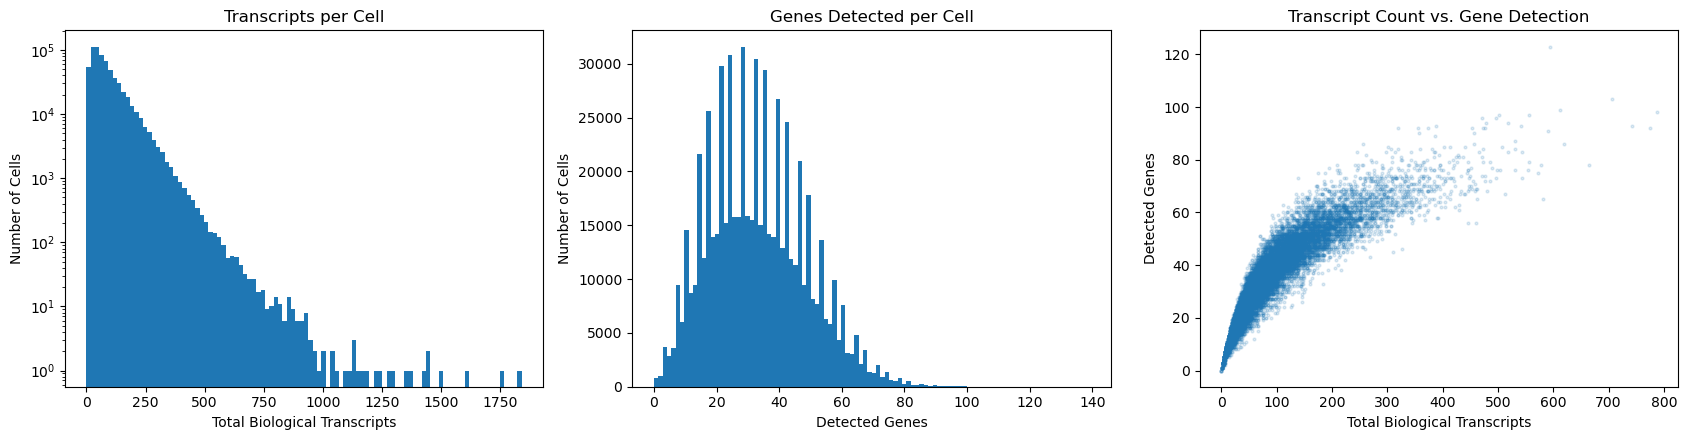

In [20]:

import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# Total biological transcripts per cell
axes[0].hist(
    adata_xenium.obs["total_transcripts"],
    bins=100
)
axes[0].set_title("Transcripts per Cell")
axes[0].set_xlabel("Total Biological Transcripts")
axes[0].set_ylabel("Number of Cells")
axes[0].set_yscale("log")

# Number of detected genes per cell
axes[1].hist(
    adata_xenium.obs["n_genes_detected"],
    bins=100
)
axes[1].set_title("Genes Detected per Cell")
axes[1].set_xlabel("Detected Genes")
axes[1].set_ylabel("Number of Cells")

# Relationship between transcripts and detected genes
rng = np.random.default_rng(42)
sample_idx = rng.choice(
    adata_xenium.n_obs,
    size=min(20000, adata_xenium.n_obs),
    replace=False
)

axes[2].scatter(
    adata_xenium.obs["total_transcripts"].to_numpy()[sample_idx],
    adata_xenium.obs["n_genes_detected"].to_numpy()[sample_idx],
    alpha=0.15,
    s=4
)
axes[2].set_title("Transcript Count vs. Gene Detection")
axes[2].set_xlabel("Total Biological Transcripts")
axes[2].set_ylabel("Detected Genes")

plt.tight_layout()
plt.show()



### 19. Evaluate Potential Cell Filtering Thresholds

Potential low-quality cells are identified using biological transcript counts and detected gene counts. Multiple candidate thresholds are evaluated to determine their effects on cell retention.

Because Xenium measures a targeted gene panel, conventional scRNA-seq filtering thresholds are not directly applicable. No filtering is performed at this stage; the results will guide selection of appropriate quality-control criteria.


In [21]:

import pandas as pd

total = adata_xenium.n_obs

thresholds = [
    (0, 0),
    (5, 3),
    (10, 5),
    (20, 10),
    (30, 15)
]

results = []

for min_transcripts, min_genes in thresholds:

    keep = (
        (adata_xenium.obs["total_transcripts"] > min_transcripts)
        & (adata_xenium.obs["n_genes_detected"] > min_genes)
    )

    n_retained = int(keep.sum())

    results.append({
        "Min transcripts (>)": min_transcripts,
        "Min genes (>)": min_genes,
        "Cells retained": n_retained,
        "Cells removed": total - n_retained,
        "Percent retained": round(n_retained / total * 100, 2)
    })

filtering_comparison = pd.DataFrame(results)

display(filtering_comparison)


,Min transcripts (>),Min genes (>),Cells retained,Cells removed,Percent retained
0,0,0,647322,202,99.97
1,5,3,641346,6178,99.05
2,10,5,627550,19974,96.92
3,20,10,581902,65622,89.87
4,30,15,519259,128265,80.19


### 20. Apply Preliminary Cell-Level QC Filtering

Cells with more than 10 detected biological transcripts and
more than 5 detected genes are retained for downstream analysis.
The original AnnData object is preserved, and filtering thresholds
will be reassessed after spatial quality assessment.

In [22]:
# Define preliminary QC thresholds
min_transcripts = 10
min_genes = 5

# Identify cells passing QC
qc_mask = (
    (adata_xenium.obs["total_transcripts"] > min_transcripts)
    & (adata_xenium.obs["n_genes_detected"] > min_genes)
)

# Create filtered AnnData object
adata_xenium_filtered = adata_xenium[qc_mask].copy()

# Summarize filtering
print("XENIUM PRELIMINARY QC FILTERING")
print("------------------------------")
print("Original cells:", adata_xenium.n_obs)
print("Retained cells:", adata_xenium_filtered.n_obs)
print("Removed cells:", adata_xenium.n_obs - adata_xenium_filtered.n_obs)
print("Genes:", adata_xenium_filtered.n_vars)

print("\nFiltered AnnData:")
print(adata_xenium_filtered)

XENIUM PRELIMINARY QC FILTERING
------------------------------
Original cells: 647524
Retained cells: 627550
Removed cells: 19974
Genes: 325

Filtered AnnData:
AnnData object with n_obs × n_vars = 627550 × 325
    obs: 'x_centroid', 'y_centroid', 'total_transcripts', 'n_genes_detected'
    var: 'gene_id', 'feature_type'
    obsm: 'spatial'
    layers: None (.X)


### 21. Evaluate Spatial Distribution of Filtered Cells

Visualize retained and removed cells to determine whether preliminary
QC filtering disproportionately affects particular tissue regions.

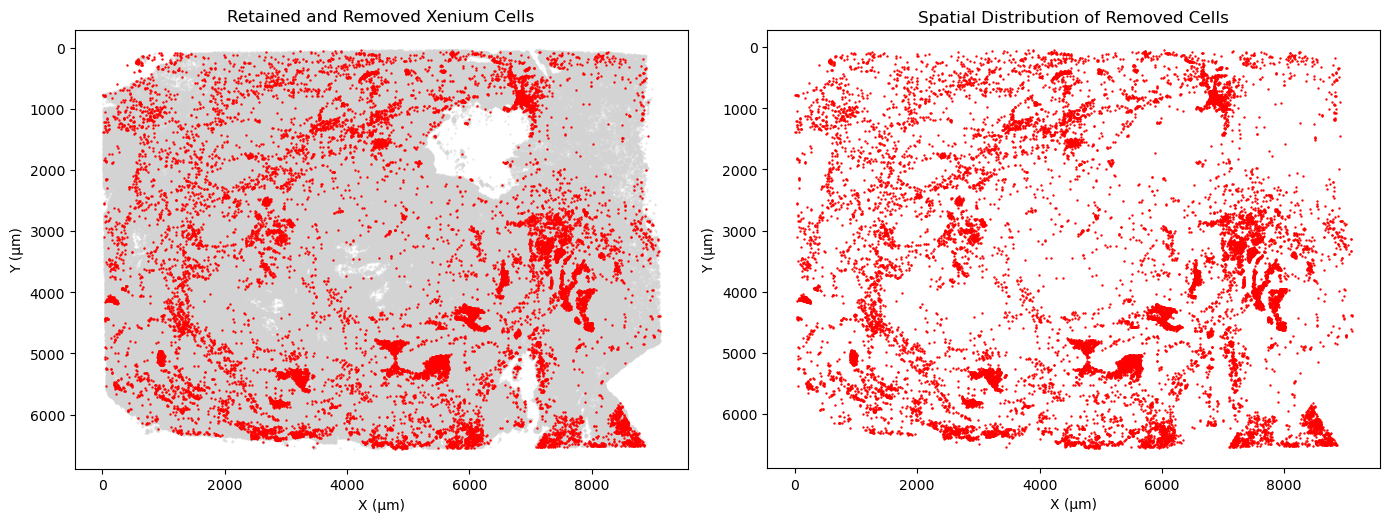

In [23]:
import matplotlib.pyplot as plt
import numpy as np

# Extract spatial coordinates
coords = adata_xenium.obsm["spatial"]

# Identify retained and removed cells
retained = np.asarray(qc_mask)
removed = ~retained

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# All cells, colored by QC status
axes[0].scatter(
    coords[retained, 0],
    coords[retained, 1],
    s=0.1,
    c="lightgray",
    rasterized=True
)

axes[0].scatter(
    coords[removed, 0],
    coords[removed, 1],
    s=0.5,
    c="red",
    rasterized=True
)

axes[0].set_title("Retained and Removed Xenium Cells")
axes[0].set_xlabel("X (µm)")
axes[0].set_ylabel("Y (µm)")
axes[0].set_aspect("equal")
axes[0].invert_yaxis()

# Removed cells only
axes[1].scatter(
    coords[removed, 0],
    coords[removed, 1],
    s=0.5,
    c="red",
    rasterized=True
)

axes[1].set_title("Spatial Distribution of Removed Cells")
axes[1].set_xlabel("X (µm)")
axes[1].set_ylabel("Y (µm)")
axes[1].set_aspect("equal")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

### 22. Quantify Regional QC Filtering Rates

Divide the tissue into spatial regions and calculate the percentage
of cells removed in each region to identify potential spatial bias.

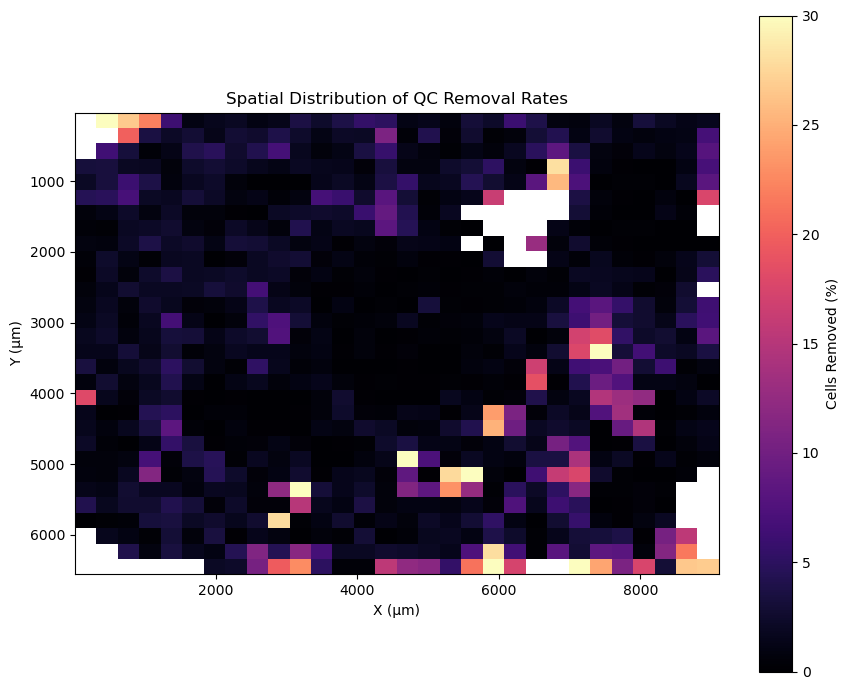

Overall removal rate: 3.08 %
Median regional removal rate: 1.42 %
Maximum regional removal rate: 45.72 %


In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

coords = adata_xenium.obsm["spatial"]
removed = ~np.asarray(qc_mask, dtype=bool)

# Divide tissue into a 30 × 30 spatial grid
n_bins = 30

x_edges = np.linspace(coords[:, 0].min(), coords[:, 0].max(), n_bins + 1)
y_edges = np.linspace(coords[:, 1].min(), coords[:, 1].max(), n_bins + 1)

# Count all cells per spatial bin
total_counts, _, _ = np.histogram2d(
    coords[:, 0], coords[:, 1],
    bins=[x_edges, y_edges]
)

# Count removed cells per spatial bin
removed_counts, _, _ = np.histogram2d(
    coords[removed, 0], coords[removed, 1],
    bins=[x_edges, y_edges]
)

# Calculate removal percentage
removal_rate = np.divide(
    removed_counts,
    total_counts,
    out=np.full_like(total_counts, np.nan),
    where=total_counts > 0
) * 100

# Mask regions with fewer than 30 cells
removal_rate[total_counts < 30] = np.nan

# Plot
fig, ax = plt.subplots(figsize=(9, 7))

im = ax.pcolormesh(
    x_edges,
    y_edges,
    removal_rate.T,
    cmap="magma",
    vmin=0,
    vmax=30,
    shading="auto"
)

plt.colorbar(im, ax=ax, label="Cells Removed (%)")

ax.set_title("Spatial Distribution of QC Removal Rates")
ax.set_xlabel("X (µm)")
ax.set_ylabel("Y (µm)")
ax.set_aspect("equal")
ax.invert_yaxis()

plt.tight_layout()
plt.show()

print("Overall removal rate:", round(removed.mean() * 100, 2), "%")
print("Median regional removal rate:", round(np.nanmedian(removal_rate), 2), "%")
print("Maximum regional removal rate:", round(np.nanmax(removal_rate), 2), "%")

### 23. Compare Cell Quality Before and After Filtering

Evaluate the impact of preliminary QC filtering on transcript
counts and detected genes per cell.

In [25]:
import pandas as pd

metrics = ["total_transcripts", "n_genes_detected"]

comparison = pd.DataFrame({
    "Before QC Median": adata_xenium.obs[metrics].median(),
    "After QC Median": adata_xenium_filtered.obs[metrics].median(),
    "Before QC Mean": adata_xenium.obs[metrics].mean(),
    "After QC Mean": adata_xenium_filtered.obs[metrics].mean()
})

display(comparison.round(2))

print("Cells before QC:", adata_xenium.n_obs)
print("Cells after QC:", adata_xenium_filtered.n_obs)
print("Percentage retained:",
      round(adata_xenium_filtered.n_obs / adata_xenium.n_obs * 100, 2))

,Before QC Median,After QC Median,Before QC Mean,After QC Mean
total_transcripts,65.0,67.0,86.92,89.47
n_genes_detected,32.0,33.0,33.18,34.05


Cells before QC: 647524
Cells after QC: 627550
Percentage retained: 96.92


### 24. Save Preliminary QC-Filtered Xenium Data

Save the filtered Xenium expression matrix, cell metadata,
gene annotations, and spatial coordinates for downstream analysis.

In [26]:
from pathlib import Path

# Define output directory
processed_dir = Path.cwd().parent / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

# Save filtered AnnData
output_file = processed_dir / "xenium_colon_qc_filtered.h5ad"

adata_xenium_filtered.write_h5ad(
    output_file,
    compression="gzip"
)

print("Filtered Xenium dataset saved!")
print("File:", output_file)
print("Cells:", adata_xenium_filtered.n_obs)
print("Genes:", adata_xenium_filtered.n_vars)
print("Spatial coordinates:", adata_xenium_filtered.obsm["spatial"].shape)

Filtered Xenium dataset saved!
File: /Users/gracescanlan/Desktop/crc_spatial_transcriptomics/data/processed/xenium_colon_qc_filtered.h5ad
Cells: 627550
Genes: 325
Spatial coordinates: (627550, 2)


### 25. Calculate Gene-Level Detection Metrics

Calculate total transcript counts, number of expressing cells,
and percentage of cells expressing each gene in the QC-filtered
Xenium dataset.

These metrics will help characterize panel coverage and guide
future selection of genes for imputation validation.

In [27]:
import numpy as np
import pandas as pd

# Use QC-filtered Xenium dataset
adata = adata_xenium_filtered

# Total transcripts detected for each gene
total_gene_counts = np.asarray(
    adata.X.sum(axis=0)
).ravel()

# Number of cells expressing each gene
n_cells_detected = np.asarray(
    (adata.X > 0).sum(axis=0)
).ravel()

# Percentage of cells expressing each gene
pct_cells_detected = (
    n_cells_detected / adata.n_obs
) * 100

# Store gene-level QC metrics
adata.var["total_transcripts"] = total_gene_counts
adata.var["n_cells_detected"] = n_cells_detected
adata.var["pct_cells_detected"] = pct_cells_detected

# Summarize gene detection
print("XENIUM GENE-LEVEL QC SUMMARY")
print("----------------------------")
print("Total genes:", adata.n_vars)

print("\nGene detection statistics:")
display(
    adata.var[
        [
            "total_transcripts",
            "n_cells_detected",
            "pct_cells_detected"
        ]
    ].describe().round(2)
)

print("\nTop 10 most frequently detected genes:")
display(
    adata.var[
        [
            "total_transcripts",
            "n_cells_detected",
            "pct_cells_detected"
        ]
    ]
    .sort_values("pct_cells_detected", ascending=False)
    .head(10)
)

print("\nBottom 10 least frequently detected genes:")
display(
    adata.var[
        [
            "total_transcripts",
            "n_cells_detected",
            "pct_cells_detected"
        ]
    ]
    .sort_values("pct_cells_detected")
    .head(10)
)

XENIUM GENE-LEVEL QC SUMMARY
----------------------------
Total genes: 325

Gene detection statistics:


,total_transcripts,n_cells_detected,pct_cells_detected
count,325.00,325.00,325.00
mean,172766.10,65745.47,10.48
std,455231.83,96216.87,15.33
min,242.00,241.00,0.04
25%,6194.00,5521.00,0.88
50%,23396.00,19809.00,3.16
75%,116579.00,78782.00,12.55
max,4282264.00,555950.00,88.59



Top 10 most frequently detected genes:


,total_transcripts,n_cells_detected,pct_cells_detected
TUBA1A,3409747,555950,88.590551
CTSB,2680793,518780,82.667517
TUBB,1424941,445249,70.950363
CD24,4282264,432730,68.955462
HMGB2,2309812,420969,67.081348
C1QBP,1459293,392407,62.529998
IGFBP7,2271532,353446,56.321568
STMN1,1227700,353202,56.282687
SLC12A2,1746177,350373,55.831886
TYMS,1517835,343885,54.798024



Bottom 10 least frequently detected genes:


,total_transcripts,n_cells_detected,pct_cells_detected
TPSG1,242,241,0.038403
MSLN,571,556,0.088599
GUCA2A,624,618,0.098478
TMEM61,707,683,0.108836
NKX2-2,895,882,0.140547
VPREB3,1053,1040,0.165724
FEV,1185,1173,0.186917
SH2D6,1301,1267,0.201896
GUCA2B,1424,1414,0.225321
TRDV1,1686,1569,0.250020


### 26. Visualize Gene-Level Detection Distributions

Examine the distribution of gene detection frequencies and total
transcript counts across the Xenium panel.

These visualizations characterize expression heterogeneity and
support future selection of held-out genes for imputation validation.

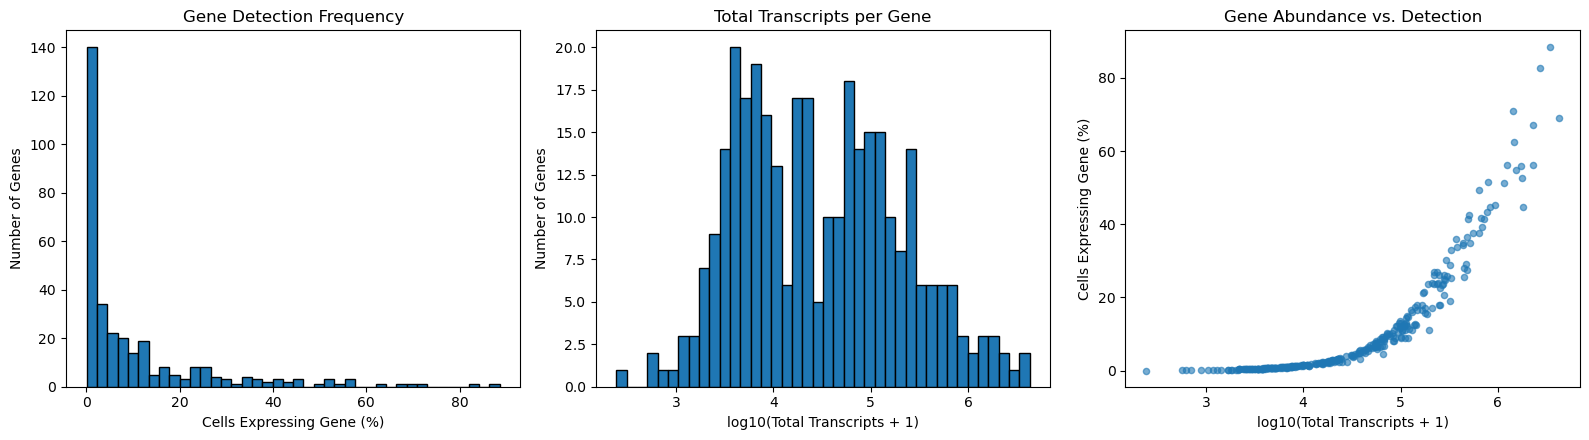

In [28]:
import matplotlib.pyplot as plt
import numpy as np

gene_metrics = adata_xenium_filtered.var

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1. Gene detection percentage
axes[0].hist(
    gene_metrics["pct_cells_detected"],
    bins=40,
    edgecolor="black"
)

axes[0].set_title("Gene Detection Frequency")
axes[0].set_xlabel("Cells Expressing Gene (%)")
axes[0].set_ylabel("Number of Genes")

# 2. Total transcript counts per gene
axes[1].hist(
    np.log10(gene_metrics["total_transcripts"] + 1),
    bins=40,
    edgecolor="black"
)

axes[1].set_title("Total Transcripts per Gene")
axes[1].set_xlabel("log10(Total Transcripts + 1)")
axes[1].set_ylabel("Number of Genes")

# 3. Relationship between abundance and detection
axes[2].scatter(
    np.log10(gene_metrics["total_transcripts"] + 1),
    gene_metrics["pct_cells_detected"],
    alpha=0.6,
    s=20
)

axes[2].set_title("Gene Abundance vs. Detection")
axes[2].set_xlabel("log10(Total Transcripts + 1)")
axes[2].set_ylabel("Cells Expressing Gene (%)")

plt.tight_layout()
plt.show()

### 27. Save Gene-Level Quality Control Metrics

Gene-level transcript abundance and detection frequency were
calculated for all 325 biological genes in the QC-filtered Xenium
dataset. These metrics will support downstream gene selection,
expression characterization, and imputation performance evaluation.

In [29]:
from pathlib import Path

# Define output directory
project_root = Path.cwd().parent
tables_dir = project_root / "results" / "tables"
tables_dir.mkdir(parents=True, exist_ok=True)

# Extract gene-level QC metrics
gene_qc_table = adata_xenium_filtered.var[
    [
        "total_transcripts",
        "n_cells_detected",
        "pct_cells_detected"
    ]
].copy()

gene_qc_table.index.name = "gene"

# Save table
output_file = tables_dir / "xenium_gene_qc_metrics.csv"
gene_qc_table.to_csv(output_file)

print("Gene-level QC metrics saved!")
print("File:", output_file)
print("Genes:", len(gene_qc_table))

display(gene_qc_table.head())

Gene-level QC metrics saved!
File: /Users/gracescanlan/Desktop/crc_spatial_transcriptomics/results/tables/xenium_gene_qc_metrics.csv
Genes: 325


,total_transcripts,n_cells_detected,pct_cells_detected
gene,,,
ABCC8,2397,2286,0.364274
ADH1C,6894,6503,1.036252
ADRA2A,13620,11507,1.833639
AFAP1L2,12052,10893,1.735798
AGTR1,5015,4748,0.756593


### 28. Save Xenium Quality Control Summary

A final quality control summary was generated to document the
original and retained cell counts, measured genes, filtering
thresholds, and cell-level expression characteristics.

The resulting dataset will be used for downstream gene
harmonization and spatial gene-imputation analysis.

In [30]:
# Create final Xenium QC summary

qc_summary = pd.DataFrame({
    "Metric": [
        "Original cells",
        "Cells after QC",
        "Cells removed",
        "Percentage retained",
        "Measured genes",
        "Minimum transcripts threshold",
        "Minimum genes threshold",
        "Median transcripts before QC",
        "Median transcripts after QC",
        "Median genes before QC",
        "Median genes after QC"
    ],
    "Value": [
        adata_xenium.n_obs,
        adata_xenium_filtered.n_obs,
        adata_xenium.n_obs - adata_xenium_filtered.n_obs,
        round(adata_xenium_filtered.n_obs / adata_xenium.n_obs * 100, 2),
        adata_xenium_filtered.n_vars,
        10,
        5,
        adata_xenium.obs["total_transcripts"].median(),
        adata_xenium_filtered.obs["total_transcripts"].median(),
        adata_xenium.obs["n_genes_detected"].median(),
        adata_xenium_filtered.obs["n_genes_detected"].median()
    ]
})

output_file = tables_dir / "xenium_qc_summary.csv"
qc_summary.to_csv(output_file, index=False)

print("Final Xenium QC summary saved!")
display(qc_summary)

Final Xenium QC summary saved!


,Metric,Value
0,Original cells,647524.00
1,Cells after QC,627550.00
2,Cells removed,19974.00
3,Percentage retained,96.92
4,Measured genes,325.00
5,Minimum transcripts threshold,10.00
6,Minimum genes threshold,5.00
7,Median transcripts before QC,65.00
8,Median transcripts after QC,67.00
9,Median genes before QC,32.00
